# 02 — Tiền xử lý và khám phá Dataset tự chơi

Notebook này **chỉ đọc artifact do `scripts/build_dataset.py` tạo ra**; không cài lại replay, split hay augmentation. Mục tiêu là hiểu nguồn dữ liệu, kiểm tra checksum/split, và quan sát sample mà PolicyNet sẽ nhận.

Dataset hiện tại có 2.000 game từ ba cặp: Heuristic–Minimax, Heuristic–MCTS và Minimax–MCTS.

In [1]:
from __future__ import annotations

import hashlib
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Chạy được khi kernel mở từ project root hoặc notebooks/.
ROOT = Path.cwd().resolve()
while not (ROOT / 'core').is_dir() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
if not (ROOT / 'core').is_dir():
    raise RuntimeError('Không tìm thấy project root (thư mục core/).')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

RAW_DIR = ROOT / 'data/raw_logs/w56_selfplay_dataset_v1'
DATASET_DIR = ROOT / 'data/processed_tensors/dataset_v1_three_agents_2000'
print('Project :', ROOT)
print('Raw     :', RAW_DIR)
print('Dataset :', DATASET_DIR)

Project : E:\2026-2027_HK1\Advanced artifical intelligence\BÀI TẬP NHÓM_TTNTNC\Team_Project_TTNTNC_2025_2026\Caro_AI_Project
Raw     : E:\2026-2027_HK1\Advanced artifical intelligence\BÀI TẬP NHÓM_TTNTNC\Team_Project_TTNTNC_2025_2026\Caro_AI_Project\data\raw_logs\w56_selfplay_dataset_v1
Dataset : E:\2026-2027_HK1\Advanced artifical intelligence\BÀI TẬP NHÓM_TTNTNC\Team_Project_TTNTNC_2025_2026\Caro_AI_Project\data\processed_tensors\dataset_v1_three_agents_2000


## 1. Manifest và tính tái lập

Manifest khóa contract, encoder, split seed và SHA-256 của artifact. Nếu checksum khác, không dùng dataset đó để train hoặc so sánh metric.

In [2]:
manifest = json.loads((DATASET_DIR / 'dataset_manifest.json').read_text(encoding='utf-8'))
validation = json.loads((DATASET_DIR / 'validation_report.json').read_text(encoding='utf-8'))
pd.Series({
    'dataset_version': manifest['dataset_version'],
    'raw_run_id': manifest['raw_run_id'],
    'contract_version': manifest['contract_version'],
    'board_size': manifest['board_size'],
    'split_seed': manifest['split_seed'],
    'D4 augmentation (train only)': manifest['train_d4_augmentation'],
})

dataset_version                     dataset-v1-three-agents-2000
raw_run_id                      w56-dataset-v1-three-agents-2000
contract_version                                         caro-v2
board_size                                                    11
split_seed                                              20261107
D4 augmentation (train only)                                True
dtype: object

In [3]:
def sha256(path: Path) -> str:
    h = hashlib.sha256()
    with path.open('rb') as f:
        for block in iter(lambda: f.read(1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

checksum_rows = []
for split, artifact in manifest['artifacts'].items():
    for kind, filename, expected in [
        ('tensor', artifact['tensor'], artifact['tensor_sha256']),
        ('metadata', artifact['metadata'], artifact['metadata_sha256']),
    ]:
        actual = sha256(DATASET_DIR / filename)
        checksum_rows.append({'split': split, 'artifact': kind, 'matches_manifest': actual == expected})
checksums = pd.DataFrame(checksum_rows)
display(checksums)
assert checksums['matches_manifest'].all(), 'Checksum mismatch: hãy build lại hoặc kiểm tra file bị thay đổi.'

,split,artifact,matches_manifest
0,train,tensor,True
1,train,metadata,True
2,val,tensor,True
3,val,metadata,True
4,test,tensor,True
5,test,metadata,True


## 2. Split theo game và tác động của dedup

Split được thực hiện bằng `game_id`, trước augmentation. Dedup ưu tiên train rồi loại bản sao ở validation/test để tránh leakage. Vì teacher có hành vi lặp, số sample cuối có thể lệch tỷ lệ game ban đầu.

,games,samples_before_dedup,duplicates_removed,samples_after_export
train,1400,46488,37696,70336
val,300,10034,8201,1833
test,300,11120,9547,1573


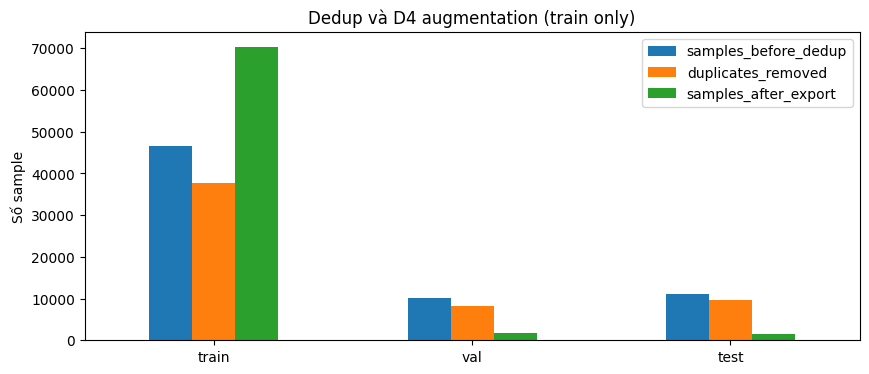

In [4]:
summary = pd.DataFrame({
    'games': validation['games'],
    'samples_before_dedup': validation['samples_before_dedup'],
    'duplicates_removed': validation['duplicates_removed'],
    'samples_after_export': validation['samples_after_export'],
})
display(summary)

ax = summary[['samples_before_dedup', 'duplicates_removed', 'samples_after_export']].plot(
    kind='bar', figsize=(10, 4), ylabel='Số sample', rot=0
)
ax.set_title('Dedup và D4 augmentation (train only)')
plt.show()

assert validation['cross_split_game_overlap'] == 0

## 3. Đọc tensor và metadata đã export

`x` có ba channel: quân người sắp đi, quân đối thủ, và ô hợp lệ. `target` là index row-major `row * 11 + col`; mọi target phải nằm trong `legal_mask`.

In [5]:
def load_split(name: str):
    tensor = np.load(DATASET_DIR / f'{name}.npz')
    meta = pd.read_json(DATASET_DIR / f'{name}_metadata.jsonl', lines=True)
    assert len(meta) == len(tensor['target'])
    assert np.all(tensor['legal_mask'][np.arange(len(tensor['target'])), tensor['target']])
    return tensor, meta

loaded = {name: load_split(name) for name in ('train', 'val', 'test')}
pd.DataFrame({
    name: {
        'x shape': data['x'].shape,
        'x dtype': str(data['x'].dtype),
        'target dtype': str(data['target'].dtype),
        'metadata rows': len(meta),
    }
    for name, (data, meta) in loaded.items()
}).T

,x shape,x dtype,target dtype,metadata rows
train,"(70336, 3, 11, 11)",float32,int64,70336
val,"(1833, 3, 11, 11)",float32,int64,1833
test,"(1573, 3, 11, 11)",float32,int64,1573


In [6]:
source_counts = pd.concat([
    meta.assign(split=name).groupby(['split', 'source_agent']).size().rename('samples')
    for name, (_, meta) in loaded.items()
]).reset_index()
display(source_counts.pivot(index='source_agent', columns='split', values='samples').fillna(0).astype(int))

pair_counts = pd.concat([
    meta.assign(split=name, pair=meta.apply(lambda r: ' vs '.join(sorted([r.x_agent, r.o_agent])), axis=1))
        .groupby(['split', 'pair']).size().rename('samples')
    for name, (_, meta) in loaded.items()
]).reset_index()
display(pair_counts.pivot(index='pair', columns='split', values='samples').fillna(0).astype(int))

split,test,train,val
source_agent,,,
heuristic,356,15336,403
mcts,787,34480,912
minimax,430,20520,518


split,test,train,val
pair,,,
heuristic vs mcts,715,29632,809
heuristic vs minimax,0,1224,0
mcts vs minimax,858,39480,1024


## 4. Decode một sample thành bàn cờ

Màu xanh là quân của người sắp đi, đỏ là đối thủ, viền xám là legal cells, và ngôi sao là nhãn teacher. Đổi `split`/`index` để xem sample khác.

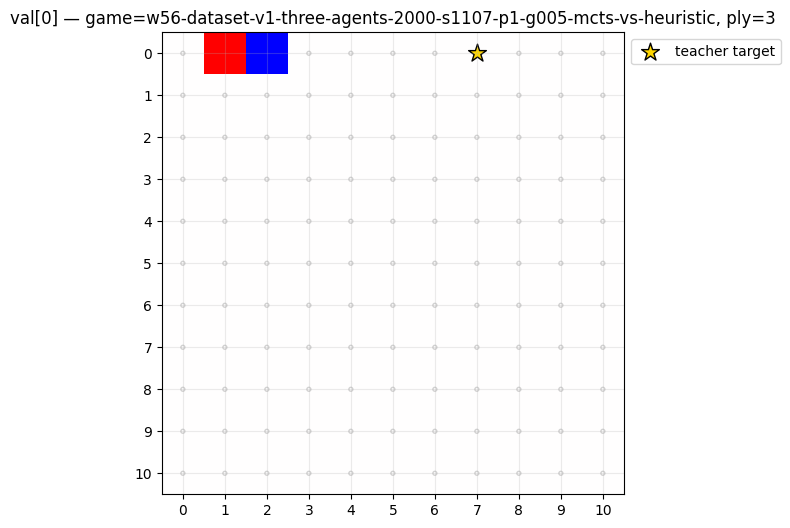

game_id         w56-dataset-v1-three-agents-2000-s1107-p1-g005...
ply                                                             3
player                                                          1
source_agent                                                 mcts
x_agent                                                      mcts
o_agent                                                 heuristic
winner                                                         -1
Name: 0, dtype: object

In [7]:
def show_sample(split='val', index=0):
    data, meta = loaded[split]
    x, target, mask = data['x'][index], int(data['target'][index]), data['legal_mask'][index]
    board = x[0] - x[1]  # +1 current player, -1 opponent
    row, col = divmod(target, 11)
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(board, cmap='bwr', vmin=-1, vmax=1)
    legal_r, legal_c = np.where(mask.reshape(11, 11))
    ax.scatter(legal_c, legal_r, s=8, facecolors='none', edgecolors='gray', alpha=.35)
    ax.scatter([col], [row], marker='*', s=180, c='gold', edgecolors='black', label='teacher target')
    ax.set_xticks(range(11)); ax.set_yticks(range(11)); ax.grid(alpha=.25)
    ax.set_title(f'{split}[{index}] — game={meta.iloc[index].game_id}, ply={meta.iloc[index].ply}')
    ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
    plt.show()
    return meta.iloc[index][['game_id', 'ply', 'player', 'source_agent', 'x_agent', 'o_agent', 'winner']]

show_sample('val', 0)

## 5. Replay một ván trên bàn cờ

Cell dưới đây đọc raw JSONL và replay action qua `CaroEnv`. `ply=0` là bàn trống; ngôi sao vàng là nước teacher sẽ đi tiếp theo. Điều này giúp bạn xem game thật, không chỉ một tensor rời.

In [4]:
from core.engine.game_env import CaroEnv
from core.ml.data_pipeline import iter_raw_games

raw_records = list(iter_raw_games(RAW_DIR / 'shard_000.jsonl'))
print(f'Đã nạp {len(raw_records)} game. Mỗi game có tối đa 121 ply.')

INITIAL_GAME_INDEX = 20  # Chỉ đổi biến này nếu muốn viewer mở sẵn một ván cụ thể.

def show_game(game_index: int = INITIAL_GAME_INDEX, ply: int = 0):
    """Hiển thị board sau `ply` nước; target là nước teacher tiếp theo."""
    record = raw_records[game_index]
    ply = min(max(0, int(ply)), len(record.moves))
    env = CaroEnv(record.config)
    for move in record.moves[:ply]:
        env.step(move.action)

    board = np.asarray(env.state.board)
    fig, ax = plt.subplots(figsize=(6.5, 6.5))
    ax.imshow(board, cmap='bwr', vmin=-1, vmax=1)
    ax.set_xticks(range(11)); ax.set_yticks(range(11)); ax.grid(alpha=.3)
    for row in range(11):
        for col in range(11):
            if board[row, col] == 1:
                ax.text(col, row, 'X', ha='center', va='center', fontsize=13, weight='bold')
            elif board[row, col] == -1:
                ax.text(col, row, 'O', ha='center', va='center', fontsize=13, weight='bold')
    if ply < len(record.moves):
        next_move = record.moves[ply]
        row, col = next_move.action
        ax.scatter([col], [row], marker='*', s=260, c='gold', edgecolors='black', label='Nước teacher kế tiếp')
        next_text = f'Next: {next_move.player.name} → {next_move.action}'
    else:
        next_text = 'Terminal state'
    ax.set_title(f'Game {game_index}: {record.x_agent} (X) vs {record.o_agent} (O) | ply {ply}/{len(record.moves)}\n{next_text}')
    ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
    plt.show()
    return pd.Series({
        'game_id': record.game_id, 'seed': record.seed, 'winner': None if record.winner is None else record.winner.name,
        'plies': len(record.moves), 'shown_after_ply': ply, 'terminal': env.is_terminal(),
    })

print('Dùng viewer liên kết ở cell kế tiếp để chọn game và ply.')

Đã nạp 2000 game. Mỗi game có tối đa 121 ply.
Dùng viewer liên kết ở cell kế tiếp để chọn game và ply.


In [ ]:
# Viewer liên kết: dropdown hiển thị game/cặp agent, không giữ output tĩnh của game 0.
try:
    import ipywidgets as widgets
    from IPython.display import display

    game_options = [
        (f'{index:04d} | {record.x_agent} (X) vs {record.o_agent} (O) | {len(record.moves)} ply', index)
        for index, record in enumerate(raw_records)
    ]
    game_selector = widgets.Dropdown(options=game_options, value=INITIAL_GAME_INDEX, description='Game', layout=widgets.Layout(width='520px'))
    ply_slider = widgets.IntSlider(min=0, max=len(raw_records[INITIAL_GAME_INDEX].moves), value=0, step=1, description='Ply', continuous_update=False)

    def sync_ply_limit(change):
        max_ply = len(raw_records[change['new']].moves)
        ply_slider.max = max_ply
        ply_slider.value = min(ply_slider.value, max_ply)

    game_selector.observe(sync_ply_limit, names='value')
    viewer_output = widgets.interactive_output(show_game, {'game_index': game_selector, 'ply': ply_slider})
    display(widgets.VBox([game_selector, ply_slider, viewer_output]))
except ImportError:
    print('ipywidgets chưa cài; dùng show_game(game_index=..., ply=...) trực tiếp.')

## 6. Cách diễn giải dataset này

- Đây là **imitation learning**: model học phân phối nước đi của Heuristic, Minimax và MCTS, không phải dữ liệu chuyên gia con người.
- Dedup cao là tín hiệu nhiều opening/trajectory giống nhau; không phải lỗi build, nhưng làm giảm độ đa dạng hiệu dụng của validation/test.
- Không dùng test để chọn kiến trúc, learning rate hay checkpoint. M1 chỉ dùng validation để early stopping; test chỉ đánh giá một lần sau khi chốt.
- Bước tiếp theo: M1 đọc `train.npz`, `val.npz`, `test.npz` để train PolicyNet với legal-mask trước loss/argmax.